In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Load the five CSV files

In [2]:
import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

DATA_PATH = "/content/drive/MyDrive/Colab data"

print(os.listdir(DATA_PATH))

['complaints-2026-05-28_00_20.csv', 'doc_ai_in_modern_vehicles.pdf', 'Beauty_dataset.pdf', 'bhagavad-gita-in-english-source-file-2.pdf', 'riders.csv', 'README.txt', 'delivery.csv', 'orders.csv', 'routes.csv', 'weather.csv']


In [3]:
orders = pd.read_csv(f"{DATA_PATH}/orders.csv")
riders = pd.read_csv(f"{DATA_PATH}/riders.csv")
routes = pd.read_csv(f"{DATA_PATH}/routes.csv")
weather = pd.read_csv(f"{DATA_PATH}/weather.csv")
delivery = pd.read_csv(f"{DATA_PATH}/delivery.csv")

datasets = {
    "Orders": orders,
    "Riders": riders,
    "Routes": routes,
    "Weather": weather,
    "Delivery": delivery
}

for name, data in datasets.items():
    print(f"{name}: {data.shape[0]} rows, {data.shape[1]} columns")

display(orders.head())

Orders: 2012 rows, 8 columns
Riders: 120 rows, 4 columns
Routes: 2000 rows, 6 columns
Weather: 2000 rows, 7 columns
Delivery: 2000 rows, 6 columns


,order_id,order_timestamp,restaurant_id,restaurant_name,restaurant_category,customer_zone,order_value_inr,order_type
0,QB100000,01-08-2026 09:03,R015,Noodle Nest,Chinese,Adyar,587.85,Delivery
1,QB100001,01-08-2026 10:07,R002,Green Bowl,Healthy,OMR,1092.12,Delivery
2,QB100002,01-08-2026 11:26,R017,Coastal Kitchen,Seafood,Mylapore,457.25,Delivery
3,QB100003,01-08-2026 11:30,R014,Salad Studio,Healthy,OMR,404.90,Scheduled
4,QB100004,01-08-2026 11:45,R014,Salad Studio,Healthy,Adyar,401.86,Delivery


## Checking data quality

In [4]:
# Check data types, missing values and duplicates

for name, data in datasets.items():
    print("\\n---", name, "---")
    print("Duplicate rows:", data.duplicated().sum())
    display(pd.DataFrame({
        "Data Type": data.dtypes.astype(str),
        "Missing Values": data.isna().sum()
    }))


\n--- Orders ---
Duplicate rows: 12


,Data Type,Missing Values
order_id,object,0
order_timestamp,object,0
restaurant_id,object,0
restaurant_name,object,0
restaurant_category,object,0
customer_zone,object,0
order_value_inr,float64,0
order_type,object,0


\n--- Riders ---
Duplicate rows: 0


,Data Type,Missing Values
rider_id,object,0
rider_name,object,0
experience_years,float64,0
shift,object,0


\n--- Routes ---
Duplicate rows: 0


,Data Type,Missing Values
route_id,object,0
order_id,object,0
distance_km,float64,0
traffic_level,object,0
zone,object,0
weather_id,object,0


\n--- Weather ---
Duplicate rows: 0


,Data Type,Missing Values
weather_id,object,0
weather_timestamp,object,0
zone,object,0
rainfall_mm,float64,35
temperature_c,float64,35
visibility_km,float64,35
weather_condition,object,35


\n--- Delivery ---
Duplicate rows: 0


,Data Type,Missing Values
delivery_id,object,0
order_id,object,0
rider_id,object,0
pickup_timestamp,object,18
delivered_timestamp,object,154
delivery_status,object,0


In [5]:
# Convert timestamp columns to datetime

orders["order_timestamp"] = pd.to_datetime(orders["order_timestamp"], errors="coerce")
delivery["pickup_timestamp"] = pd.to_datetime(delivery["pickup_timestamp"], errors="coerce")
delivery["delivered_timestamp"] = pd.to_datetime(delivery["delivered_timestamp"], errors="coerce")
weather["weather_timestamp"] = pd.to_datetime(weather["weather_timestamp"], errors="coerce")

# Check unusual values
duration = (delivery["delivered_timestamp"] - delivery["pickup_timestamp"]).dt.total_seconds() / 60

print("Duplicate order IDs:", orders["order_id"].duplicated().sum())
print("Negative pickup-to-delivery durations:", (duration < 0).sum())
print("Missing pickup timestamps:", delivery["pickup_timestamp"].isna().sum())
print("Missing delivered timestamps:", delivery["delivered_timestamp"].isna().sum())


Duplicate order IDs: 12
Negative pickup-to-delivery durations: 1
Missing pickup timestamps: 1202
Missing delivered timestamps: 1251


## Clean and combine the datasets

In [6]:
# Remove duplicate orders
orders = orders.drop_duplicates(subset="order_id").copy()

# Standardize zone names
def clean_zone(value):
    if pd.isna(value):
        return np.nan
    value = re.sub(r"[-_]+", " ", str(value).strip().lower())
    value = re.sub(r"\\s+", " ", value)
    mapping = {
        "anna nagar": "Anna Nagar", "t nagar": "T Nagar",
        "velachery": "Velachery", "omr": "OMR", "adyar": "Adyar",
        "tambaram": "Tambaram", "porur": "Porur", "mylapore": "Mylapore",
        "guindy": "Guindy", "nungambakkam": "Nungambakkam"
    }
    return mapping.get(value, value.title())

orders["customer_zone"] = orders["customer_zone"].apply(clean_zone)
routes["zone"] = routes["zone"].apply(clean_zone)
weather["zone"] = weather["zone"].apply(clean_zone)

# Join the datasets using their shared IDs
data = orders.merge(routes, on="order_id", how="left", validate="one_to_one")
data = data.merge(weather.drop(columns=["zone"], errors="ignore"),
                  on="weather_id", how="left", validate="many_to_one")
data = data.merge(delivery, on="order_id", how="left", validate="one_to_one")
data = data.merge(riders, on="rider_id", how="left", validate="many_to_one")

print("Combined dataset shape:", data.shape)
display(data.head())


Combined dataset shape: (2000, 26)


,order_id,order_timestamp,restaurant_id,restaurant_name,restaurant_category,customer_zone,order_value_inr,order_type,route_id,distance_km,traffic_level,zone,weather_id,weather_timestamp,rainfall_mm,temperature_c,visibility_km,weather_condition,delivery_id,rider_id,pickup_timestamp,delivered_timestamp,delivery_status,rider_name,experience_years,shift
0,QB100000,2026-01-08 09:03:00,R015,Noodle Nest,Chinese,Adyar,587.85,Delivery,RT000000,11.12,Very High,Adyar,WX000000,2026-01-08 09:03:00,0.0,25.6,6.7,Clear/Cloudy,DL000000,RD034,2026-01-08 09:07:00,2026-01-08 10:19:00,Delivered,Rider_034,1.4,Morning
1,QB100001,2026-01-08 10:07:00,R002,Green Bowl,Healthy,OMR,1092.12,Delivery,RT000001,13.72,High,OMR,WX000001,2026-01-08 10:07:00,1.8,29.4,2.9,Light Rain,DL000001,RD026,2026-01-08 10:11:00,2026-01-08 11:13:00,Delivered Late,Rider_026,1.5,Morning
2,QB100002,2026-01-08 11:26:00,R017,Coastal Kitchen,Seafood,Mylapore,457.25,Delivery,RT000002,1.63,High,Mylapore,WX000002,2026-01-08 11:26:00,0.0,29.5,5.2,Clear/Cloudy,DL000002,RD025,2026-01-08 11:27:00,2026-01-08 11:34:00,Delivered,Rider_025,1.5,Afternoon
3,QB100003,2026-01-08 11:30:00,R014,Salad Studio,Healthy,OMR,404.90,Scheduled,RT000003,1.34,High,OMR,WX000003,2026-01-08 11:30:00,0.0,26.8,9.2,Clear/Cloudy,DL000003,RD101,2026-01-08 11:33:00,2026-01-08 11:39:00,Delivered,Rider_101,1.1,Afternoon
4,QB100004,2026-01-08 11:45:00,R014,Salad Studio,Healthy,Adyar,401.86,Delivery,RT000004,2.55,Medium,Adyar,WX000004,2026-01-08 11:45:00,0.4,30.2,5.6,Light Rain,DL000004,RD053,2026-01-08 11:46:00,2026-01-08 11:52:00,Delivered,Rider_053,2.4,Afternoon


## Create useful features and clean invalid durations

In [7]:
# Create time durations in minutes

data["pickup_duration_min"] = (
    data["pickup_timestamp"] - data["order_timestamp"]
).dt.total_seconds() / 60

data["delivery_duration_min"] = (
    data["delivered_timestamp"] - data["pickup_timestamp"]
).dt.total_seconds() / 60

data["total_delivery_min"] = (
    data["delivered_timestamp"] - data["order_timestamp"]
).dt.total_seconds() / 60

data["order_hour"] = data["order_timestamp"].dt.hour

def time_period(hour):
    if pd.isna(hour):
        return "Unknown"
    if 11 <= hour < 15:
        return "Lunch Peak"
    if 18 <= hour < 22:
        return "Dinner Peak"
    if 6 <= hour < 11:
        return "Morning"
    if 15 <= hour < 18:
        return "Afternoon"
    return "Night"

data["time_period"] = data["order_hour"].apply(time_period)

# Exclude impossible negative durations and rows without total delivery time
data = data[
    (data["pickup_duration_min"].isna() | (data["pickup_duration_min"] >= 0)) &
    (data["delivery_duration_min"].isna() | (data["delivery_duration_min"] >= 0)) &
    (data["total_delivery_min"].notna()) &
    (data["total_delivery_min"] >= 0)
].copy()

print("Rows available for analysis:", len(data))
print("Average total delivery time:", round(data["total_delivery_min"].mean(), 2), "minutes")
print("Average pickup time:", round(data["pickup_duration_min"].mean(), 2), "minutes")


Rows available for analysis: 748
Average total delivery time: 85.75 minutes
Average pickup time: 3.01 minutes


## Analyze delivery time by zone

,mean,median,count
customer_zone,,,
Mylapore,675.42,18.5,64
Tambaram,37.15,35.0,72
OMR,37.00,34.0,99
Porur,33.97,28.0,69
Guindy,30.08,29.0,61
T Nagar,29.34,25.0,83
Velachery,28.27,27.0,81
Nungambakkam,26.98,23.0,43
Adyar,26.43,24.0,69


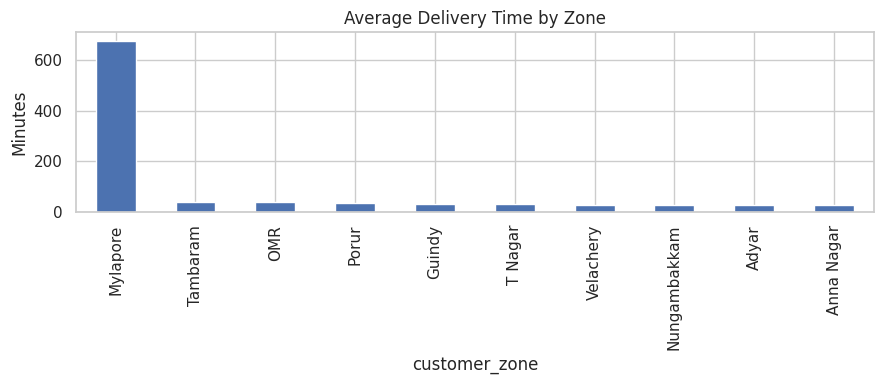

In [8]:
zone_result = data.groupby("customer_zone")["total_delivery_min"].agg(
    ["mean", "median", "count"]
).sort_values("mean", ascending=False)

display(zone_result.round(2))

zone_result["mean"].plot(kind="bar", figsize=(9, 4), title="Average Delivery Time by Zone")
plt.ylabel("Minutes")
plt.tight_layout()
plt.show()


## Traffic and weather impact

,mean,count
traffic_level,,
Low,21.39,119
High,31.17,252
Very High,47.15,106
Medium,179.87,271


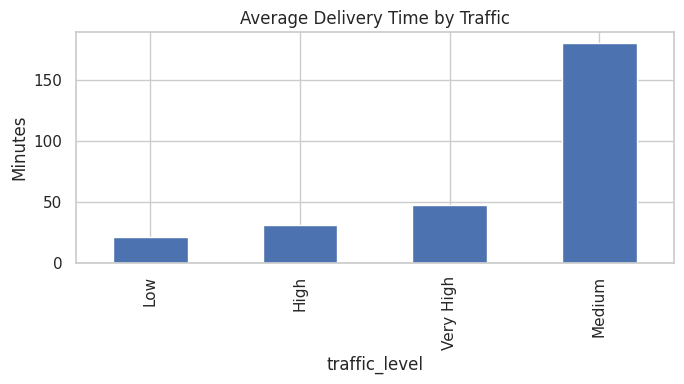

,mean,count
rain_status,,
No Rain,29.65,400
Rain,155.01,335


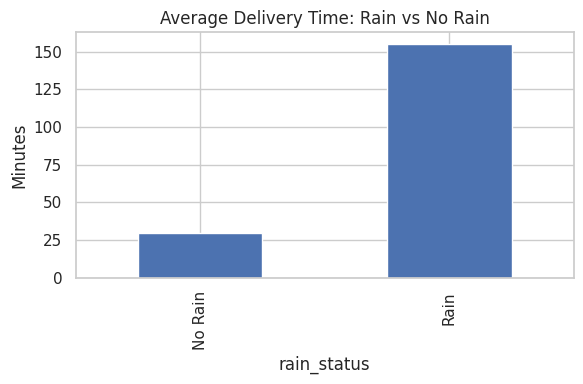

In [9]:
traffic_result = data.groupby("traffic_level")["total_delivery_min"].agg(
    ["mean", "count"]
).sort_values("mean")

display(traffic_result.round(2))
traffic_result["mean"].plot(kind="bar", title="Average Delivery Time by Traffic", figsize=(7, 4))
plt.ylabel("Minutes")
plt.tight_layout()
plt.show()

# Compare rainy and non-rainy orders where rainfall data exists
rain_data = data.dropna(subset=["rainfall_mm"]).copy()
rain_data["rain_status"] = np.where(rain_data["rainfall_mm"] > 0, "Rain", "No Rain")
rain_result = rain_data.groupby("rain_status")["total_delivery_min"].agg(["mean", "count"])

display(rain_result.round(2))
rain_result["mean"].plot(kind="bar", title="Average Delivery Time: Rain vs No Rain", figsize=(6, 4))
plt.ylabel("Minutes")
plt.tight_layout()
plt.show()


## Restaurant pickup time

,mean,count
restaurant_name,,
Wrap & Roll,3.50,34
Noodle Nest,3.32,38
Sandwich Lab,3.26,34
Dosa Corner,3.26,38
Pasta Point,3.23,30
Coastal Kitchen,3.17,41
Wok Express,3.14,29
Burger Bay,3.11,46
Cafe Cloud,3.06,31


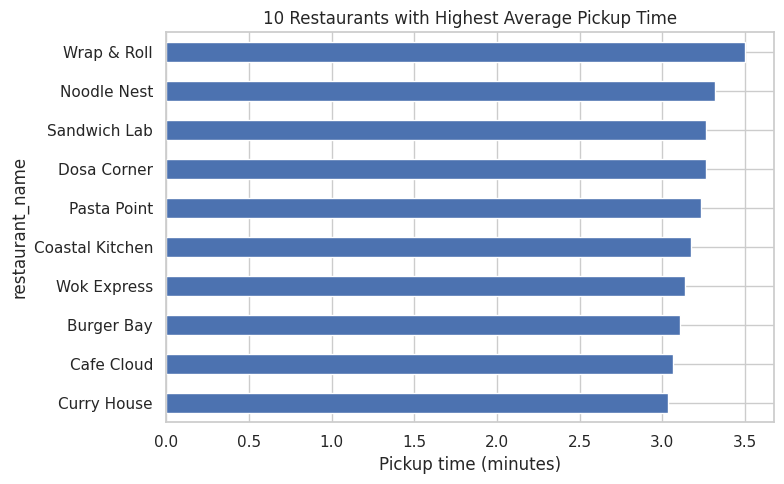

In [10]:
restaurant_result = data.groupby("restaurant_name")["pickup_duration_min"].agg(
    ["mean", "count"]
).sort_values("mean", ascending=False)

display(restaurant_result.head(10).round(2))

restaurant_result.head(10)["mean"].sort_values().plot(
    kind="barh", figsize=(8, 5), title="10 Restaurants with Highest Average Pickup Time"
)
plt.xlabel("Pickup time (minutes)")
plt.tight_layout()
plt.show()


## Distance and peak-hour analysis

Distance vs total delivery time correlation: -0.018


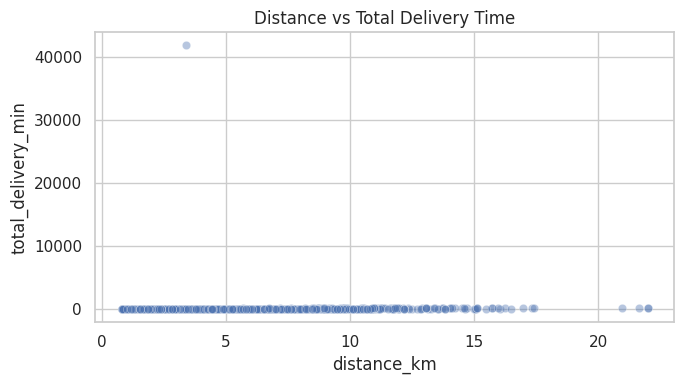

,mean,count
order_hour,,
8.0,27.75,16
9.0,26.92,13
10.0,27.40,10
11.0,29.42,62
12.0,27.80,98
13.0,30.32,78
14.0,20.63,27
15.0,27.09,11
16.0,25.94,18


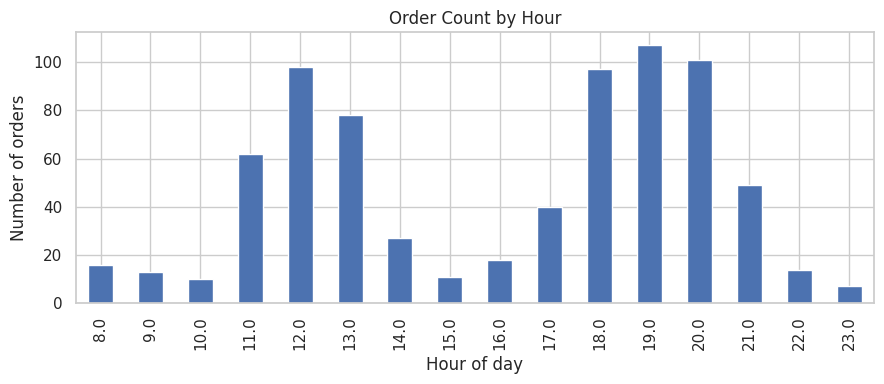

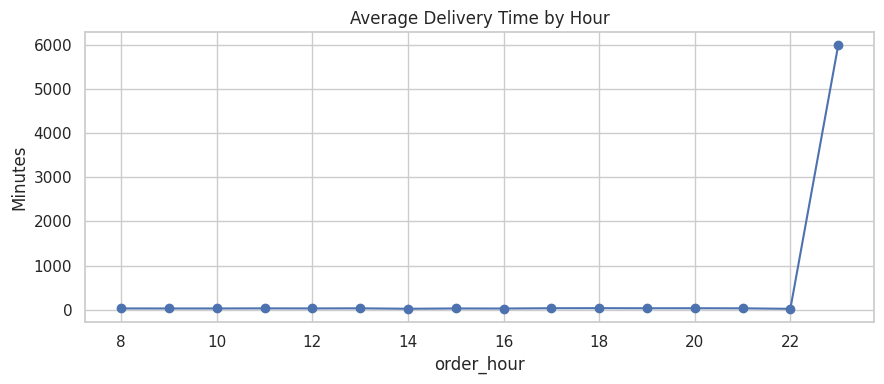

In [11]:
print("Distance vs total delivery time correlation:",
      round(data[["distance_km", "total_delivery_min"]].corr().iloc[0, 1], 3))

plt.figure(figsize=(7, 4))
sns.scatterplot(data=data, x="distance_km", y="total_delivery_min", alpha=0.4)
plt.title("Distance vs Total Delivery Time")
plt.tight_layout()
plt.show()

hour_result = data.groupby("order_hour")["total_delivery_min"].agg(
    ["mean", "count"]
)

display(hour_result.round(2))

hour_result["count"].plot(kind="bar", figsize=(9, 4), title="Order Count by Hour")
plt.xlabel("Hour of day")
plt.ylabel("Number of orders")
plt.tight_layout()
plt.show()

hour_result["mean"].plot(kind="line", marker="o", figsize=(9, 4),
                         title="Average Delivery Time by Hour")
plt.ylabel("Minutes")
plt.tight_layout()
plt.show()


## Encode categories and select useful features

In [12]:
# Simple encoding example for analysis; keep the original data unchanged
encoded_data = pd.get_dummies(
    data[["traffic_level", "weather_condition", "customer_zone", "time_period"]],
    columns=["traffic_level", "weather_condition", "customer_zone", "time_period"],
    dtype=int
)

print("Encoded categorical data shape:", encoded_data.shape)
display(encoded_data.head())


Encoded categorical data shape: (748, 23)


,traffic_level_High,traffic_level_Low,traffic_level_Medium,traffic_level_Very High,weather_condition_Clear/Cloudy,weather_condition_Heavy Rain,weather_condition_Light Rain,weather_condition_Moderate Rain,customer_zone_Adyar,customer_zone_Anna Nagar,customer_zone_Guindy,customer_zone_Mylapore,customer_zone_Nungambakkam,customer_zone_OMR,customer_zone_Porur,customer_zone_T Nagar,customer_zone_Tambaram,customer_zone_Velachery,time_period_Afternoon,time_period_Dinner Peak,time_period_Lunch Peak,time_period_Morning,time_period_Night
0,0,0,0,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0
1,1,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0
2,1,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0
3,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0
4,0,0,1,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0


In [13]:
# Simple feature selection using correlation with total delivery time
numeric_features = [
    "distance_km", "order_value_inr", "experience_years",
    "rainfall_mm", "temperature_c", "visibility_km",
    "pickup_duration_min", "order_hour", "total_delivery_min"
]

feature_corr = data[numeric_features].corr(numeric_only=True)["total_delivery_min"]
feature_corr = feature_corr.drop("total_delivery_min").sort_values(
    key=lambda values: values.abs(), ascending=False
)

print("Numeric features most associated with total delivery time:")
display(feature_corr.to_frame("Correlation with total delivery time"))


Numeric features most associated with total delivery time:


,Correlation with total delivery time
order_hour,0.066669
pickup_duration_min,-0.051865
temperature_c,-0.045984
visibility_km,0.024417
distance_km,-0.017505
order_value_inr,-0.009269
experience_years,0.004450
rainfall_mm,0.001756


## Save the cleaned dataset

In [15]:
OUTPUT_PATH = "/content/drive/MyDrive/Colab data/cleaned_food_delivery.csv"
data.to_csv(OUTPUT_PATH, index=False)

print("Cleaned dataset saved to:", OUTPUT_PATH)
print("Final dataset shape:", data.shape)


Cleaned dataset saved to: /content/drive/MyDrive/Colab data/cleaned_food_delivery.csv
Final dataset shape: (748, 31)


In [16]:

# Select input features
features = [
    "distance_km",
    "order_value_inr",
    "experience_years",
    "rainfall_mm",
    "temperature_c",
    "visibility_km",
    "order_hour",
    "traffic_level",
    "weather_condition",
    "customer_zone",
    "time_period"
]

target = "total_delivery_min"

# Create the input and target data
model_data = data[features + [target]].copy()

# Remove rows where the target is missing
model_data = model_data.dropna(subset=[target])

X = model_data[features]
y = model_data[target]

print("Input features:", features)
print("Target variable:", target)
print("Number of records:", len(model_data))


Input features: ['distance_km', 'order_value_inr', 'experience_years', 'rainfall_mm', 'temperature_c', 'visibility_km', 'order_hour', 'traffic_level', 'weather_condition', 'customer_zone', 'time_period']
Target variable: total_delivery_min
Number of records: 748


In [17]:

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Separate numerical and categorical features
numeric_features = [
    "distance_km", "order_value_inr", "experience_years",
    "rainfall_mm", "temperature_c", "visibility_km", "order_hour"
]

categorical_features = [
    "traffic_level", "weather_condition", "customer_zone", "time_period"
]

# Handle missing values and encode categorical columns
numeric_process = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_process = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_process, numeric_features),
    ("categorical", categorical_process, categorical_features)
])

# Create the Random Forest model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ))
])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train and predict
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# Evaluate model performance
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("Model: Random Forest Regressor")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("MAE:", round(mae, 2), "minutes")
print("RMSE:", round(rmse, 2), "minutes")
print("R² Score:", round(r2, 3))


Model: Random Forest Regressor
Training records: 598
Testing records: 150
MAE: 4.05 minutes
RMSE: 5.17 minutes
R² Score: 0.9
